# Satellite Orbit Explorer · built during Space Career Week 2026 · GNSS Academy

### Project Phases
1. **Configuration** (Current Phase)
2. **GP JSON Loading**
3. **Element Interpretation**
4. **Time Interval**
5. **Propagation**
6. **Orbit Summary**
7. **Plots & Visualizations**
8. **KML & Report Export**

In [1]:
# --- 1. Imports ---
import json
import math
import time
import zipfile
import xml.etree.ElementTree as ET
from datetime import datetime, timedelta, timezone
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import requests

# --- 2. Physical Constants (Standard: km, km/s) ---
MU_EARTH_KM3_S2 = 398600.4418  # Gravitational parameter of the Earth [km^3/s^2]
EARTH_RADIUS_KM = 6378.137      # Equatorial Earth radius [km]

# --- 3. Working Directories ---
BASE_DIR = Path('/content/satellite_orbits')
IN_DIR = BASE_DIR / 'input'
OUT_DIR = BASE_DIR / 'output'

# Create directories if they do not exist
IN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- 4. Default Parameters Configuration ---
STEP_SECONDS = 5
DURATION_HOURS = 24
LIVE_GROUP = 'STATIONS'  # Configured for live download from CelesTrak

# --- 5. Veritas and Requirements Assertions ---
assert IN_DIR.is_dir(), "Error: Input directory does not exist."
assert OUT_DIR.is_dir(), "Error: Output directory does not exist."
assert STEP_SECONDS == 5, "Error: STEP_SECONDS is not configured correctly."
assert DURATION_HOURS == 24, "Error: DURATION_HOURS is not configured correctly."
assert LIVE_GROUP is None or isinstance(LIVE_GROUP, str), "Error: LIVE_GROUP must be None or a valid string."

print("=== PHASE 1 CONFIGURATION COMPLETED SUCCESSFULLY ===")
print(f"Input Directory:  {IN_DIR} (Verified)")
print(f"Output Directory: {OUT_DIR} (Verified)")
print(f"Constants:         MU_EARTH = {MU_EARTH_KM3_S2} km^3/s^2, EARTH_RADIUS = {EARTH_RADIUS_KM} km")
print(f"Parameters:        Step = {STEP_SECONDS}s, Duration = {DURATION_HOURS}h, Live Group = {LIVE_GROUP}")

=== PHASE 1 CONFIGURATION COMPLETED SUCCESSFULLY ===
Input Directory:  /content/satellite_orbits/input (Verified)
Output Directory: /content/satellite_orbits/output (Verified)
Constants:         MU_EARTH = 398600.4418 km^3/s^2, EARTH_RADIUS = 6378.137 km
Parameters:        Step = 5s, Duration = 24h, Live Group = STATIONS


## Phase 2: Loading GP JSON

The OMM (Orbit Mean-Elements Message) JSON format is significantly simpler than the legacy TLE (Two-Line Element set) format because it associates each parameter with an explicit, self-explanatory key, avoiding the need to parse fixed-character positions. In addition, it natively supports standardized and easy-to-parse formats such as ISO 8601 timestamps and extended numerical satellite catalog identifiers (NORAD IDs) with six or more digits without any spatial limitations.

In [2]:
def extract_inputs():
    """Verifies the presence of the required input files or waits for the user to upload the ZIP archive to extract them."""
    required_files = ['orbital_elements.json', 'data_manifest.json', 'world_map.txt']
    all_present = all((IN_DIR / f).is_file() for f in required_files)

    if all_present:
        print("All required input files are already present in IN_DIR.")
        return

    print("Required input files are missing from IN_DIR.")
    print("--> INSTRUCTION: Drag and drop the 'orbit_workshop_inputs.zip' file into the '/content' folder of Colab (left panel).")

    content_dir = Path('/content')
    zip_path = None
    timeout = 900  # 15 minutes
    start_time = time.time()

    # Polling loop to detect the uploaded zip file
    while True:
        if time.time() - start_time > timeout:
            raise TimeoutError("Time limit exceeded (15 minutes). No upload detected. Please try again.")

        # Search for zip files starting with 'orbit_workshop_inputs'
        zip_candidates = list(content_dir.glob('orbit_workshop_inputs*.zip'))
        if zip_candidates:
            candidate = zip_candidates[0]
            if zipfile.is_zipfile(candidate):
                zip_path = candidate
                print(f"Valid ZIP file detected: {zip_path.name}. Starting extraction...")
                break

        time.sleep(2)

    # Target extraction of only the 3 required files into the IN_DIR folder
    with zipfile.ZipFile(zip_path, 'r') as zf:
        namelist = zf.namelist()
        for f_name in required_files:
            # Find the file within the zip (it might be nested)
            matched = [member for member in namelist if member.endswith(f_name)]
            if not matched:
                raise FileNotFoundError(f"Could not find {f_name} inside the ZIP archive.")

            member_to_extract = matched[0]
            # Physically extract the file content
            data = zf.read(member_to_extract)
            target_path = IN_DIR / f_name
            target_path.write_bytes(data)
            print(f"Extracted: {f_name} -> {target_path}")


def read_gp_json(path):
    """Loads the GP JSON list and validates its fundamental OMM fields."""
    if not path.is_file():
        raise FileNotFoundError(f"File not found: {path}")

    with open(path, 'r') as f:
        try:
            data = json.load(f)
        except json.JSONDecodeError as e:
            raise ValueError(f"The file {path.name} is not a valid JSON: {e}")

    if not isinstance(data, list):
        raise ValueError("The JSON file must contain a list of records.")

    required_keys = {
        'OBJECT_NAME', 'NORAD_CAT_ID', 'EPOCH', 'MEAN_MOTION',
        'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE',
        'ARG_OF_PERICENTER', 'MEAN_ANOMALY'
    }

    for idx, record in enumerate(data):
        missing_keys = required_keys - record.keys()
        if missing_keys:
            raise ValueError(f"Record {idx} ({record.get('OBJECT_NAME', 'Unnamed')}) is missing the following OMM fields: {missing_keys}")

    return data

# --- Execution of Phase 2 Steps ---
# 1. Extraction or verification of inputs
extract_inputs()

# 2. Loading and validation of satellite records
sats = read_gp_json(IN_DIR / 'orbital_elements.json')

# 3. Loading the manifest and printing the metadata information
with open(IN_DIR / 'data_manifest.json', 'r') as f:
    data_manifest = json.load(f)

source_note = f"Data loaded from CelesTrak. Retrieved on (UTC): {data_manifest['retrieved_utc']}"
print(f"\nSource Note: {source_note}\n")

print(f"Found {len(sats)} validated satellites:")
print(f"{'Satellite Name':<25} | {'NORAD ID':<10} | {'Epoch (UTC)':<25}")
print("-" * 68)
for s in sats:
    print(f"{s['OBJECT_NAME']:<25} | {s['NORAD_CAT_ID']:<10} | {s['EPOCH']:<25}")

Required input files are missing from IN_DIR.
--> INSTRUCTION: Drag and drop the 'orbit_workshop_inputs.zip' file into the '/content' folder of Colab (left panel).
Valid ZIP file detected: orbit_workshop_inputs.zip. Starting extraction...
Extracted: orbital_elements.json -> /content/satellite_orbits/input/orbital_elements.json
Extracted: data_manifest.json -> /content/satellite_orbits/input/data_manifest.json
Extracted: world_map.txt -> /content/satellite_orbits/input/world_map.txt

Source Note: Data loaded from CelesTrak. Retrieved on (UTC): 2026-11-10T16:30:32Z

Found 4 validated satellites:
Satellite Name            | NORAD ID   | Epoch (UTC)              
--------------------------------------------------------------------
PULSAR-0                  | 64541      | 2026-11-10T04:10:34.900320
GSAT0225 (GALILEO 29)     | 59598      | 2026-11-09T08:30:06.579648
SES-5                     | 38652      | 2026-11-10T04:02:09.139776
QZS-2 (MICHIBIKI-2)       | 42738      | 2026-10-17T15:21:5

In [5]:
# --- Optional Extension: Live Data from CelesTrak ---
import json
import time
import requests
from datetime import datetime, timezone

# 1. Rigorous check of the presence of LIVE_GROUP from Phase 1
if 'LIVE_GROUP' not in globals():
    raise NameError("LIVE_GROUP not defined: Make sure to run the Phase 1 cell first.")

if LIVE_GROUP is None:
    print("LIVE_GROUP is None: The offline snapshot from the workshop will be used without downloading new data.")
else:
    cache_file = IN_DIR / f'gp_{LIVE_GROUP}.json'
    cache_expired = True

    # Check cache age (2 hours = 7200 seconds)
    if cache_file.is_file():
        file_age_seconds = time.time() - cache_file.stat().st_mtime
        if file_age_seconds < 7200:
            cache_expired = False
            print(f"Found valid cache file for group '{LIVE_GROUP}' (age: {file_age_seconds/60:.1f} minutes). Loading...")

    if cache_expired:
        url = f"https://celestrak.org/NORAD/elements/gp.php?GROUP={LIVE_GROUP}&FORMAT=JSON"
        print(f"Downloading live data for group '{LIVE_GROUP}' from CelesTrak...")

        response = requests.get(url, timeout=30)
        response.raise_for_status()
        live_data = response.json()

        # 2. Data validation BEFORE caching it
        if not isinstance(live_data, list) or len(live_data) < 4:
            raise ValueError("Downloaded data from CelesTrak does not contain at least 4 orbital records.")

        for idx, sat in enumerate(live_data):
            if not isinstance(sat, dict) or 'NORAD_CAT_ID' not in sat:
                raise ValueError(f"Record at index {idx} in downloaded data is not a valid GP record.")

        # Save to cache only if data is valid
        with open(cache_file, 'w', encoding='utf-8') as f:
            json.dump(live_data, f, indent=2)
        print(f"Data successfully validated and cached: {cache_file.name}")

    # 3. Final load and verification of cached data
    with open(cache_file, 'r', encoding='utf-8') as f:
        live_sats = json.load(f)

    if not isinstance(live_sats, list) or len(live_sats) < 4:
        raise ValueError("Cached data does not contain at least 4 valid GP records.")

    # Sort by NORAD_CAT_ID (converted to int) and select the first 4 records
    sorted_sats = sorted(live_sats, key=lambda x: int(x['NORAD_CAT_ID']))
    sats = sorted_sats[:4]

    # Update the origin note including the live group
    retrieved_time = datetime.fromtimestamp(cache_file.stat().st_mtime, tz=timezone.utc)
    source_note = f"Live data loaded from CelesTrak for group '{LIVE_GROUP}'. Retrieved on (UTC): {retrieved_time.strftime('%Y-%m-%dT%H:%M:%SZ')}"

    print(f"\nUpdated Source Note: {source_note}\n")
    print(f"Selected the first 4 sorted satellites from group '{LIVE_GROUP}':")
    print(f"{'Satellite Name':<25} | {'NORAD ID':<10} | {'Epoch (UTC)':<25}")
    print("-" * 68)
    for s in sats:
        print(f"{s['OBJECT_NAME']:<25} | {s['NORAD_CAT_ID']:<10} | {s['EPOCH']:<25}")

Data successfully validated and cached: gp_STATIONS.json

Updated Source Note: Live data loaded from CelesTrak for group 'STATIONS'. Retrieved on (UTC): 2026-11-15T23:44:03Z

Selected the first 4 sorted satellites from group 'STATIONS':
Satellite Name            | NORAD ID   | Epoch (UTC)              
--------------------------------------------------------------------
ISS (ZARYA)               | 25544      | 2026-11-15T08:02:34.132128
POISK                     | 36086      | 2026-11-15T08:02:34.132128
CSS (TIANHE)              | 48274      | 2026-11-15T11:04:07.567680
ISS (NAUKA)               | 49044      | 2026-11-15T08:02:34.132128


## Phase 3: Interpretation of Elements

The data downloaded from CelesTrak are **SGP4 Mean Elements**. These parameters average out the effects of real perturbing forces such as atmospheric drag and non-spherical Earth gravity ($J_2$, $J_3$, etc.). Since our simulator uses a simplified two-body model (pure Keplerian), considering these mean parameters directly as osculating Keplerian elements represents an **educational approximation** and not a precision calculation.

### Parameter Table and Conversions

| GP JSON Field | Keplerian Symbol | Original Unit | Model Unit | Conversion Formula |
| :--- | :---: | :--- | :--- | :--- |
| `MEAN_MOTION` | $n$ | Revolutions / Day | rad/s | $n_{	ext{rad/s}} = rac{2 	imes 	ext{revolutions/day}}{86400}$ |
| - (Calculated) | $a$ | - | km | $a = 	ext{cube_root}(rac{\mu}{n_{\text{rad/s}}^2})$ (Kepler's Third Law) |
| `ECCENTRICITY` | $e$ | Decimal | Decimal | Direct |
| `INCLINATION` | $i$ | Degrees | Radians | $i_{\text{rad}} = i_{\text{deg}} 	imes rac{\pi}{180}$ |
| `RA_OF_ASC_NODE` | $\Omega$ | Degrees | Radians | $\Omega_{\text{rad}} = \Omega_{\text{deg}} 	imes rac{\pi}{180}$ |
| `ARG_OF_PERICENTER` | $\omega$ | Degrees | Radians | $\omega_{\text{rad}} = \omega_{\text{deg}} 	imes rac{\pi}{180}$ |
| `MEAN_ANOMALY` | $M_0$ | Degrees | Radians | $M_{0,\text{rad}} = M_{0,\text{deg}} 	imes rac{\pi}{180}$ |

In [3]:
def parse_gp_epoch(text):
    """Converts a CelesTrak ISO 8601 UTC time string into a timezone-aware UTC datetime object."""
    # Removes any trailing 'Z' and sets the timezone to UTC
    clean_text = text.rstrip('Z')
    return datetime.fromisoformat(clean_text).replace(tzinfo=timezone.utc)


def parse_gp_elements(rec):
    """Converts a GP record into the core Keplerian parameters needed for propagation."""
    # Extract textual fields and identifiers
    name = rec['OBJECT_NAME']
    norad_id = int(rec['NORAD_CAT_ID'])
    label = f"{name} [{norad_id}]"
    epoch = parse_gp_epoch(rec['EPOCH'])

    # Convert Mean Motion from rev/day to rad/s
    mean_motion_rev_day = rec['MEAN_MOTION']
    n_rad_s = (2 * math.pi * mean_motion_rev_day) / 86400.0

    # Calculate Semi-major Axis (a) in km using Kepler's Third Law: a^3 = MU / n^2
    a_km = (MU_EARTH_KM3_S2 / (n_rad_s ** 2)) ** (1.0 / 3.0)

    # Eccentricity (already unitless decimal)
    e = float(rec['ECCENTRICITY'])

    # Convert angles from degrees to radians
    i_rad = math.radians(rec['INCLINATION'])
    raan_rad = math.radians(rec['RA_OF_ASC_NODE'])
    argp_rad = math.radians(rec['ARG_OF_PERICENTER'])
    M0_rad = math.radians(rec['MEAN_ANOMALY'])

    return {
        'name': name,
        'norad_id': norad_id,
        'label': label,
        'epoch': epoch,
        'n_rad_s': n_rad_s,
        'a_km': a_km,
        'e': e,
        'i_rad': i_rad,
        'raan_rad': raan_rad,
        'argp_rad': argp_rad,
        'M0_rad': M0_rad
    }


def elements_table(elements_list):
    """Generates and returns formatted rows of a text table with the orbital elements."""
    headers = f"{'Satellite Name':<23} | {'NORAD':<6} | {'Epoch (UTC)':<24} | {'a [km]':<10} | {'e':<8} | {'i [°]':<6} | {'Ω [°]':<6} | {'ω [°]':<6} | {'M0 [°]':<6}"
    separator = "-" * len(headers)

    rows = [headers, separator]
    for el in elements_list:
        # Convert radians back to degrees for the printed table view
        i_deg = math.degrees(el['i_rad'])
        raan_deg = math.degrees(el['raan_rad'])
        argp_deg = math.degrees(el['argp_rad'])
        M0_deg = math.degrees(el['M0_rad'])

        row = (f"{el['name']:<23} | {el['norad_id']:<6} | "
               f"{el['epoch'].isoformat().replace('+00:00', ''):<24} | "
               f"{el['a_km']:<10.2f} | {el['e']:<8.6f} | "
               f"{i_deg:<6.1f} | {raan_deg:<6.1f} | {argp_deg:<6.1f} | {M0_deg:<6.1f}")
        rows.append(row)

    return "\n".join(rows)

# --- Checking Previous Phases and Execution ---
if 'sats' not in globals():
    raise NameError("Error: Satellite data ('sats') from Phase 2 is not loaded in memory. Run Phase 2 first.")

# Convert all GP records
elements = [parse_gp_elements(s) for s in sats]

# Generate and print elements table
table_output = elements_table(elements)
print("=== CONVERTED KEPLERIAN ELEMENTS (PHASE 3) ===")
print(table_output)

=== CONVERTED KEPLERIAN ELEMENTS (PHASE 3) ===
Satellite Name          | NORAD  | Epoch (UTC)              | a [km]     | e        | i [°]  | Ω [°]  | ω [°]  | M0 [°]
-----------------------------------------------------------------------------------------------------------------------
PULSAR-0                | 64541  | 2026-11-10T04:10:34.900320 | 6880.97    | 0.000408 | 97.5   | 67.6   | 54.2   | 306.0 
GSAT0225 (GALILEO 29)   | 59598  | 2026-11-09T08:30:06.579648 | 29600.26   | 0.000159 | 55.2   | 97.0   | 171.2  | 226.9 
SES-5                   | 38652  | 2026-11-10T04:02:09.139776 | 42164.28   | 0.000191 | 0.1    | 32.2   | 188.0  | 254.7 
QZS-2 (MICHIBIKI-2)     | 42738  | 2026-10-17T15:21:52.982784 | 42170.36   | 0.074521 | 39.2   | 241.4  | 270.9  | 243.8 


## Phase 4: Time Interval

Defining a common time grid is essential to visualize and compare the positions of multiple satellites simultaneously. However, it is important to remember that each orbital parameter record is propagated starting from its own specific `epoch`.

Since the simplified two-body Keplerian model ignores real perturbations, the position error grows progressively as the time offset from the original epoch increases. In our default dataset, the record for the **QZS-2** satellite dates back to October 17, 2026. Being more than 23 days away from the start of the reference simulation, the results for this specific satellite will have a very high error and must be considered purely indicative (*stale record*).

In [4]:
# --- Checking Previous Phases ---
if 'elements' not in globals():
    raise NameError("Error: Keplerian elements ('elements') from Phase 3 are not in memory. Run Phase 3 first.")

# --- 1. Calculating Common Grid Start and End ---
# Find the most recent epoch among all satellites
latest_epoch = max(el['epoch'] for el in elements)

# Round down to midnight UTC of the same day
start = datetime(latest_epoch.year, latest_epoch.month, latest_epoch.day, tzinfo=timezone.utc)
end = start + timedelta(hours=DURATION_HOURS)

# --- 2. Creating the Time Grid ---
total_duration_seconds = int((end - start).total_seconds())
# Number of points including start and end
n_points = (total_duration_seconds // STEP_SECONDS) + 1

times = [start + timedelta(seconds=i * STEP_SECONDS) for i in range(n_points)]

# --- 3. Printing and Checking Record Age (Offset) ---
print("=== TIME INTERVAL CONFIGURATION (PHASE 4) ===")
print(f"Common Start (UTC):     {start.isoformat()}")
print(f"Common End (UTC):       {end.isoformat()}")
print(f"Sampling Step:          {STEP_SECONDS} seconds")
print(f"Total Number of Points: {n_points}\n")

print("Analysis of the time offset (Start - Epoch) for each satellite:")
print(f"{'Satellite Name':<25} | {'Offset (Days)':<20} | {'Record Status':<15}")
print("-" * 66)

for el in elements:
    offset_days = (start - el['epoch']).total_seconds() / 86400.0

    # Flag records as stale if the offset is greater than 7 days
    if offset_days > 7.0:
        status = "[STALE RECORD]"
    else:
        status = "OK"

    print(f"{el['name']:<25} | {offset_days:<20.2f} | {status:<15}")

=== TIME INTERVAL CONFIGURATION (PHASE 4) ===
Common Start (UTC):     2026-11-10T00:00:00+00:00
Common End (UTC):       2026-11-11T00:00:00+00:00
Sampling Step:          5 seconds
Total Number of Points: 17281

Analysis of the time offset (Start - Epoch) for each satellite:
Satellite Name            | Offset (Days)        | Record Status  
------------------------------------------------------------------
PULSAR-0                  | -0.17                | OK             
GSAT0225 (GALILEO 29)     | 0.65                 | OK             
SES-5                     | -0.17                | OK             
QZS-2 (MICHIBIKI-2)       | 23.36                | [STALE RECORD] 


In [6]:
def solve_kepler(M, e):
    """Solves Kepler's Equation M = E - e * sin(E) using the Newton-Raphson method."""
    # Standard initial guess
    E = math.pi if e > 0.8 else M
    tolerance = 1e-12
    max_iterations = 50

    for _ in range(max_iterations):
        f = E - e * math.sin(E) - M
        df = 1.0 - e * math.cos(E)
        delta = f / df
        E -= delta
        if abs(delta) < tolerance:
            return E

    raise RuntimeError(f"Newton-Raphson method did not converge for M={M}, e={e}")


def gmst_rad(t):
    """Calculates Greenwich Mean Sidereal Time (GMST) in radians for a given UTC datetime."""
    # J2000 reference Epoch (12:00 UTC on January 1, 2000)
    j2000 = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
    delta_time = t - j2000
    d = delta_time.total_seconds() / 86400.0

    # Julian centuries elapsed since J2000
    T = d / 36525.0

    # IAU-1982 formula for GMST in degrees
    theta_deg = 280.46061837 + 360.98564736629 * d + 0.000387933 * (T ** 2) - (T ** 3) / 38710000.0
    theta_deg = theta_deg % 360.0

    return math.radians(theta_deg)


def propagate(el, time_grid):
    """Propagates the satellite orbit over a common time grid."""
    # Extract satellite physical parameters
    epoch = el['epoch']
    n = el['n_rad_s']
    a = el['a_km']
    e = el['e']
    i = el['i_rad']
    raan = el['raan_rad']
    argp = el['argp_rad']
    M0 = el['M0_rad']

    track = []

    for t in time_grid:
        dt_seconds = (t - epoch).total_seconds()

        # 1) Calculate Mean Anomaly M
        M = (M0 + n * dt_seconds) % (2.0 * math.pi)

        # 2) Solve Kepler's Equation for Eccentric Anomaly E
        E = solve_kepler(M, e)

        # 3) Calculate radial distance (r), true anomaly (nu), and argument of latitude (u)
        r = a * (1.0 - e * math.cos(E))
        sin_nu = (math.sqrt(1.0 - e**2) * math.sin(E))
        cos_nu = (math.cos(E) - e)
        nu = math.atan2(sin_nu, cos_nu)
        u = argp + nu

        # 4) Calculate inertial spatial coordinates (x-axis pointing to Vernal Equinox)
        x_iner = r * (math.cos(raan) * math.cos(u) - math.sin(raan) * math.sin(u) * math.cos(i))
        y_iner = r * (math.sin(raan) * math.cos(u) + math.cos(raan) * math.sin(u) * math.cos(i))
        z_iner = r * math.sin(u) * math.sin(i)

        # 5) Coordinate rotation with Earth's spin (ECEF) using the GMST angle theta
        theta = gmst_rad(t)
        x_rot = math.cos(theta) * x_iner + math.sin(theta) * y_iner
        y_rot = -math.sin(theta) * x_iner + math.cos(theta) * y_iner

        # 6) Calculate spherical latitude, longitude (wrapped in [-180, 180]), and altitude
        lat_deg = math.degrees(math.atan2(z_iner, math.hypot(x_rot, y_rot)))
        lon_deg = math.degrees(math.atan2(y_rot, x_rot))
        # Longitude normalization
        lon_deg = (lon_deg + 180.0) % 360.0 - 180.0
        alt_km = r - EARTH_RADIUS_KM

        # 7) Calculate instantaneous speed using the vis-viva equation
        speed_km_s = math.sqrt(MU_EARTH_KM3_S2 * (2.0 / r - 1.0 / a))

        track.append({
            'time': t,
            'lat_deg': lat_deg,
            'lon_deg': lon_deg,
            'alt_km': alt_km,
            'speed_km_s': speed_km_s
        })

    return track

# ==============================================================================
# VERIFICATION TESTS WITH ASSERTS
# ==============================================================================
# Test 1: GMST at J2000 (12:00 UTC on January 1, 2000)
j2000_test = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
gmst_j2000_deg = math.degrees(gmst_rad(j2000_test))
assert abs(gmst_j2000_deg - 280.46061837) < 1e-5, f"Error in GMST J2000: {gmst_j2000_deg}"

# Test 2: Mathematical robustness of Kepler Solver (Combinatorial Grid Test)
test_eccentricities = [0.0001, 0.01, 0.05, 0.1, 0.5, 0.8, 0.9]
test_mean_anomalies = [0.0, 0.5, 1.0, math.pi, 4.0, 5.5, 2 * math.pi]

for e_test in test_eccentricities:
    for M_test in test_mean_anomalies:
        E_test = solve_kepler(M_test, e_test)
        residual = abs(E_test - e_test * math.sin(E_test) - M_test)
        # Handle periodicity residue around 2*pi
        if residual > math.pi:
            residual = abs(residual - 2 * math.pi)
        assert residual < 1e-10, f"Kepler solver residue failed for M={M_test}, e={e_test}. Residue: {residual}"

# --- Control and Propagation of Orbits ---
if 'elements' not in globals() or 'times' not in globals():
    raise NameError("Previous phase not executed. Missing 'elements' or 'times'.")

tracks = [propagate(el, times) for el in elements]

# Test 3: Verification of SES-5 (NORAD 38652) longitude limits between 4 and 6 degrees East
ses5_idx = next((idx for idx, el in enumerate(elements) if el['norad_id'] == 38652), None)
if ses5_idx is not None:
    ses5_track = tracks[ses5_idx]
    for pt in ses5_track:
        lon = pt['lon_deg']
        assert 4.0 <= lon <= 6.0, f"Error: SES-5 is outside the geostationary boundaries (4°E - 6°E). Detected: {lon}°"

print("=== PROPAGATION AND VALIDATION TESTS COMPLETED SUCCESSFULLY ===\n")

# --- Print Key Points (First, Middle, Last) ---
for idx, el in enumerate(elements):
    track = tracks[idx]
    n_pts = len(track)
    print(f"Satellite: {el['label']}")
    print(f"  {'-'*70}")
    for label, pos in [("First    ", 0), ("Middle   ", n_pts // 2), ("Last     ", n_pts - 1)]:
        pt = track[pos]
        time_str = pt['time'].strftime('%H:%M:%S')
        print(f"  {label} ({time_str}) | Lat: {pt['lat_deg']:>7.2f}° | Lon: {pt['lon_deg']:>7.2f}° | Alt: {pt['alt_km']:>8.1f} km | Vel: {pt['speed_km_s']:>6.3f} km/s")
    print("\n")

=== PROPAGATION AND VALIDATION TESTS COMPLETED SUCCESSFULLY ===

Satellite: PULSAR-0 [64541]
  ----------------------------------------------------------------------
  First     (00:00:00) | Lat:   51.99° | Lon: -151.86° | Alt:    502.0 km | Vel:  7.612 km/s
  Middle    (12:00:00) | Lat:  -14.79° | Lon: -160.05° | Alt:    501.8 km | Vel:  7.612 km/s
  Last      (00:00:00) | Lat:  -22.73° | Lon: -165.68° | Alt:    505.2 km | Vel:  7.608 km/s


Satellite: GSAT0225 (GALILEO 29) [59598]
  ----------------------------------------------------------------------
  First     (00:00:00) | Lat:   52.28° | Lon:  111.76° | Alt:  23222.7 km | Vel:  3.670 km/s
  Middle    (12:00:00) | Lat:   17.32° | Lon: -120.13° | Alt:  23226.2 km | Vel:  3.669 km/s
  Last      (00:00:00) | Lat:  -25.70° | Lon:   27.34° | Alt:  23226.4 km | Vel:  3.669 km/s


Satellite: SES-5 [38652]
  ----------------------------------------------------------------------
  First     (00:00:00) | Lat:    0.02° | Lon:    5.00° | Alt

## Phase 6: Orbit Summary

In this phase, we consolidate the geometric and kinematic orbital metrics calculated for each satellite, extracting the minimum and maximum tangential velocities and validating the physical consistency of our orbits.

In [7]:
def orbit_summary(el, pts):
    """Calculates orbital summary parameters and velocity extremes for the satellite."""
    name = el['name']
    norad_id = el['norad_id']
    a = el['a_km']
    e = el['e']
    n = el['n_rad_s']
    i_deg = math.degrees(el['i_rad'])

    # Calculate orbital period in hours: T = (2 * pi / n) / 3600
    period_h = (2.0 * math.pi / n) / 3600.0

    # Calculate perigee and apogee altitudes above the Earth's surface
    perigee_km = a * (1.0 - e) - EARTH_RADIUS_KM
    apogee_km = a * (1.0 + e) - EARTH_RADIUS_KM

    # Extract minimum and maximum velocities recorded in the propagated points
    speeds = [pt['speed_km_s'] for pt in pts]
    min_v = min(speeds)
    max_v = max(speeds)

    return {
        'name': name,
        'norad_id': norad_id,
        'period_h': period_h,
        'perigee_km': perigee_km,
        'apogee_km': apogee_km,
        'e': e,
        'i_deg': i_deg,
        'min_v_km_s': min_v,
        'max_v_km_s': max_v
    }


def summary_table(summaries_list):
    """Generates and returns the formatted text table rows of the orbital summaries."""
    headers = f"{'Satellite Name':<23} | {'NORAD':<6} | {'Period [h]':<11} | {'Perigee [km]':<12} | {'Apogee [km]':<11} | {'e':<8} | {'i [°]':<6} | {'V_min [km/s]':<12} | {'V_max [km/s]':<12}"
    separator = "-" * len(headers)

    rows = [headers, separator]
    for s in summaries_list:
        row = (f"{s['name']:<23} | {s['norad_id']:<6} | "
               f"{s['period_h']:<11.2f} | {s['perigee_km']:<12.1f} | {s['apogee_km']:<11.1f} | "
               f"{s['e']:<8.6f} | {s['i_deg']:<6.1f} | {s['min_v_km_s']:<12.3f} | {s['max_v_km_s']:<12.3f}")
        rows.append(row)

    return rows

# --- Checking and Generating Summaries ---
if 'elements' not in globals() or 'tracks' not in globals():
    raise NameError("Previous phase not completed. Missing 'elements' or 'tracks'.")

summaries = [orbit_summary(el, pts) for el, pts in zip(elements, tracks)]

# --- Assertion Test for Galileo 29 (NORAD 59598) ---
galileo_sum = next((s for s in summaries if s['norad_id'] == 59598), None)
if galileo_sum is not None:
    period = galileo_sum['period_h']
    assert 14.0 <= period <= 14.2, f"Error: Galileo 29 period is outside the expected range (14.0 - 14.2 h). Detected: {period:.2f} h"

# Generate and save the table rows for future use (Phase 8)
table_rows = summary_table(summaries)

print("=== ORBITAL SUMMARY GENERATED SUCCESSFULLY (PHASE 6) ===")
print("\n".join(table_rows))

=== ORBITAL SUMMARY GENERATED SUCCESSFULLY (PHASE 6) ===
Satellite Name          | NORAD  | Period [h]  | Perigee [km] | Apogee [km] | e        | i [°]  | V_min [km/s] | V_max [km/s]
-----------------------------------------------------------------------------------------------------------------------------
PULSAR-0                | 64541  | 1.58        | 500.0        | 505.6       | 0.000408 | 97.5   | 7.608        | 7.614       
GSAT0225 (GALILEO 29)   | 59598  | 14.08       | 23217.4      | 23226.8     | 0.000159 | 55.2   | 3.669        | 3.670       
SES-5                   | 38652  | 23.93       | 35778.1      | 35794.2     | 0.000191 | 0.1    | 3.074        | 3.075       
QZS-2 (MICHIBIKI-2)     | 42738  | 23.94       | 32649.6      | 38934.8     | 0.074521 | 39.2   | 2.853        | 3.313       


### Physical Interpretation and Orbital Regimes of the Satellites

Analyzing the newly generated orbital summary table, we can classify and interpret the behavior of each spacecraft based on physical orbital dynamics:

1. **PULSAR-0**:
   - **Period**: $\approx 1.58 \text{ hours}$ ($95 \text{ minutes}$).
   - **Inclination**: $\approx 97.5^\circ$.
   - **Interpretation**: This represents a very low Earth orbit (**LEO - Low Earth Orbit**), which is almost circular ($e \approx 0.0004$). The inclination higher than $90^\circ$ indicates a **retrograde** orbit; specifically, an inclination near $97^\circ-98^\circ$ at this altitude is typical of a near-polar **Sun-Synchronous Orbit (SSO)**. This allows the satellite to fly over any given point on the Earth's surface at the same local mean solar time.

2. **GSAT0225 (GALILEO 29)**:
   - **Period**: $\approx 14.08 \text{ hours}$ (confirmed between $14.0$ and $14.2 \text{ hours}$ by our assertion).
   - **Inclination**: $\approx 55.2^\circ$.
   - **Interpretation**: Positioned in a Medium Earth Orbit (**MEO**), typical for global navigation constellations (such as GPS, GLONASS, and Galileo). The orbital period of approximately 14 hours and $55^\circ$ inclination ensure outstanding global geometric coverage and repeatable ground passes.

3. **SES-5**:
   - **Period**: $\approx 23.93 \text{ hours}$ ($1 \text{ sidereal day} \approx 86164 \text{ seconds}$).
   - **Inclination**: $\approx 0.1^\circ$.
   - **Eccentricity**: Nearly zero ($e \approx 0.0002$).
   - **Interpretation**: This satellite resides in a perfect **Geostationary Orbit (GEO)**. The nearly zero inclination (lying on the equatorial plane) and extremely low eccentricity ensure that as the satellite rotates at the exact same angular velocity as Earth, it remains stationary above a fixed point on the Earth's surface at $5.0^\circ$ East.

4. **QZS-2 (MICHIBIKI-2)**:
   - **Period**: $\approx 23.93 \text{ hours}$ ($1 \text{ sidereal day}$).
   - **Eccentricity**: $\approx 0.075$.
   - **Inclination**: $\approx 39.2^\circ$.
   - **Interpretation**: Despite sharing the same Earth-synchronous period as SES-5, its high inclination ($39.2^\circ$) and non-negligible eccentricity mean **it is not a geostationary satellite**, but rather an **Inclined Geosynchronous Orbit (IGSO)** satellite. It traces a characteristic asymmetric "figure-8" shape on the Earth's surface (an *analemma*), optimized to dwell for long periods at high elevation angles over Japan and East Asia.

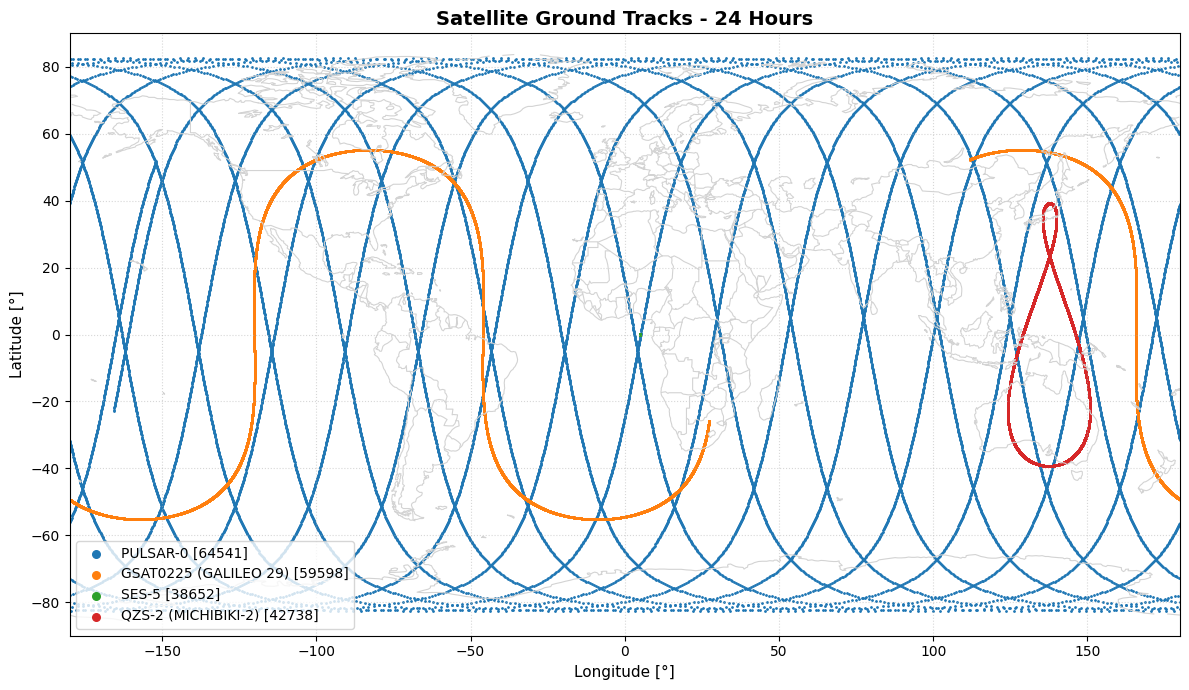

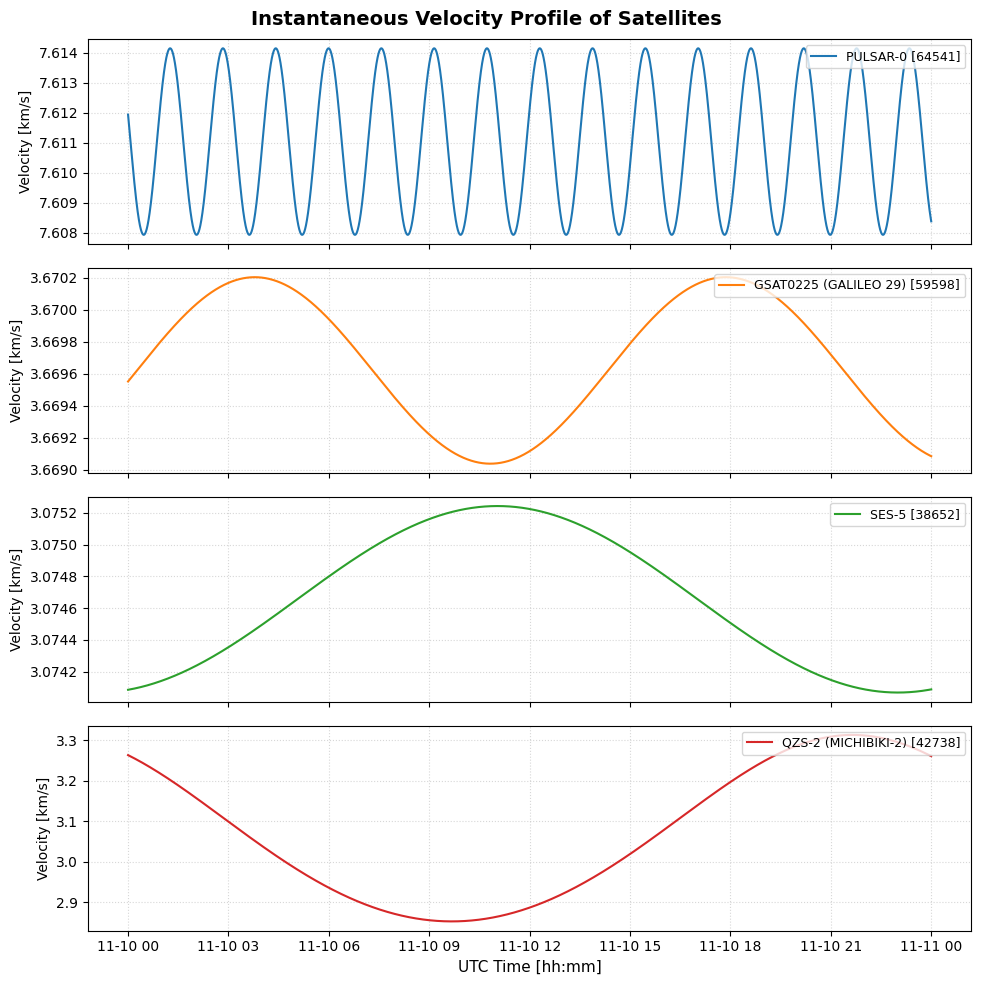

In [8]:
def load_coastline(path):
    """Loads coastlines from a file where each line contains 'latitude longitude'.

    Empty lines separate different coastline segments.
    Returns a list of segments, where each segment is a list of tuples (lon, lat).
    """
    if not path.is_file():
        raise FileNotFoundError(f"Map file not found: {path}")

    segments = []
    current_segment = []

    with open(path, 'r') as f:
        for line in f:
            stripped = line.strip()
            if not stripped:
                if current_segment:
                    segments.append(current_segment)
                    current_segment = []
            else:
                parts = stripped.split()
                if len(parts) >= 2:
                    # Format specifications: latitude FIRST, longitude SECOND
                    lat = float(parts[0])
                    lon = float(parts[1])
                    current_segment.append((lon, lat))

    if current_segment:
        segments.append(current_segment)

    return segments

# --- 1. Colors Definition (Phase 7 & 8) ---
COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

# --- 2. Loading Coastline ---
coastline_segments = load_coastline(IN_DIR / 'world_map.txt')

# --- 3. FIGURE 1: Ground Tracks ---
plt.figure(figsize=(12, 7))

# Draw coastline in light gray
for seg in coastline_segments:
    lons = [pt[0] for pt in seg]
    lats = [pt[1] for pt in seg]
    plt.plot(lons, lats, color='lightgray', linewidth=0.8)

# Draw ground track for each satellite
for idx, (el, track) in enumerate(zip(elements, tracks)):
    color = COLORS[idx % len(COLORS)]
    sat_lons = [pt['lon_deg'] for pt in track]
    sat_lats = [pt['lat_deg'] for pt in track]

    # Use scatter with tiny markers to avoid artificial lines when wrapping around +/-180 longitude
    plt.scatter(sat_lons, sat_lats, color=color, s=1, label=el['label'])

plt.title("Satellite Ground Tracks - 24 Hours", fontsize=14, fontweight='bold')
plt.xlabel("Longitude [°]", fontsize=11)
plt.ylabel("Latitude [°]", fontsize=11)
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(True, linestyle=':', alpha=0.5)

# Customize legend to show visible marker sizes
lgnd = plt.legend(loc="lower left", fontsize=10, markerscale=6)
for handle in lgnd.legend_handles:
    handle._sizes = [30]

plt.tight_layout()
plt.savefig(OUT_DIR / 'ground_tracks.png', dpi=200)
plt.show()

# --- 4. FIGURE 2: Velocity Time Series ---
fig, axs = plt.subplots(len(elements), 1, figsize=(10, 10), sharex=True)

for idx, (el, track) in enumerate(zip(elements, tracks)):
    ax = axs[idx]
    color = COLORS[idx % len(COLORS)]

    sat_times = [pt['time'] for pt in track]
    sat_speeds = [pt['speed_km_s'] for pt in track]

    ax.plot(sat_times, sat_speeds, color=color, linewidth=1.5, label=el['label'])
    ax.set_ylabel("Velocity [km/s]", fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.legend(loc="upper right", fontsize=9)

    # Avoid exponential or offset notation on the y-axis
    ax.get_yaxis().get_major_formatter().set_useOffset(False)

axs[-1].set_xlabel("UTC Time [hh:mm]", fontsize=11)
plt.suptitle("Instantaneous Velocity Profile of Satellites", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(OUT_DIR / 'velocity_timeseries.png', dpi=150)
plt.show()

In [9]:
import xml.etree.ElementTree as ET

# --- Checking Previous Phases ---
required_vars = ['elements', 'tracks', 'summaries', 'COLORS', 'OUT_DIR', 'source_note', 'start', 'end', 'STEP_SECONDS', 'table_rows']
for var in required_vars:
    if var not in globals():
        raise NameError(f"Error: Variable '{var}' is not in memory. Make sure you run all previous phases.")

# Properly register the namespace for KML (ElementTree handles this automatically without duplications)
ET.register_namespace('', 'http://www.opengis.net/kml/2.2')
ET.register_namespace('gx', 'http://www.google.com/kml/ext/2.2')

def matplotlib_to_kml_color(matplotlib_color):
    """Converts a Matplotlib color (hex or string) to KML aabbggrr format."""
    hex_color = to_hex(matplotlib_color)  # Formats '#rrggbb'
    r = hex_color[1:3]
    g = hex_color[3:5]
    b = hex_color[5:7]
    a = 'ff'  # 100% opacity
    return f"{a}{b}{g}{r}"

# ==============================================================================
# 1. GENERATING 'orbit_tracks_ecef.kml'
# ==============================================================================
kml_ecef = ET.Element('kml', xmlns='http://www.opengis.net/kml/2.2')
document_ecef = ET.SubElement(kml_ecef, 'Document')

title_ecef = ET.SubElement(document_ecef, 'name')
title_ecef.text = 'Multi-Satellite Orbits | Earth-fixed'

# Define color styles for each satellite
for idx, el in enumerate(elements):
    color_kml = matplotlib_to_kml_color(COLORS[idx % len(COLORS)])

    style = ET.SubElement(document_ecef, 'Style', id=f"style_{el['norad_id']}")

    # Line Style
    line_style = ET.SubElement(style, 'LineStyle')
    color_elem = ET.SubElement(line_style, 'color')
    color_elem.text = color_kml
    width = ET.SubElement(line_style, 'width')
    width.text = '3'

    # Icon Style
    icon_style = ET.SubElement(style, 'IconStyle')
    icon_color = ET.SubElement(icon_style, 'color')
    icon_color.text = color_kml
    scale = ET.SubElement(icon_style, 'scale')
    scale.text = '1.0'
    icon = ET.SubElement(icon_style, 'Icon')
    href = ET.SubElement(icon, 'href')
    href.text = 'http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png'

# Add Placemarks with 3D orbital lines
for idx, (el, track) in enumerate(zip(elements, tracks)):
    placemark = ET.SubElement(document_ecef, 'Placemark')

    name_elem = ET.SubElement(placemark, 'name')
    name_elem.text = el['name']

    style_url = ET.SubElement(placemark, 'styleUrl')
    style_url.text = f"#style_{el['norad_id']}"

    line_string = ET.SubElement(placemark, 'LineString')

    extrude = ET.SubElement(line_string, 'extrude')
    extrude.text = '0'

    tessellate = ET.SubElement(line_string, 'tessellate')
    tessellate.text = '1'

    alt_mode = ET.SubElement(line_string, 'altitudeMode')
    alt_mode.text = 'absolute'

    # Construct the coordinate string 'lon,lat,alt' (altitude in meters)
    coord_list = []
    for pt in track:
        alt_meters = pt['alt_km'] * 1000.0
        coord_list.append(f"{pt['lon_deg']:.6f},{pt['lat_deg']:.6f},{alt_meters:.1f}")

    coords = ET.SubElement(line_string, 'coordinates')
    coords.text = ' '.join(coord_list)

tree_ecef = ET.ElementTree(kml_ecef)
tree_ecef.write(OUT_DIR / 'orbit_tracks_ecef.kml', encoding='utf-8', xml_declaration=True)
print("Successfully created: orbit_tracks_ecef.kml")

# ==============================================================================
# 2. GENERATING 'orbit_animation.kml'
# ==============================================================================
# Define root elements including standard namespaces to avoid duplicate attributes
kml_anim = ET.Element('kml', xmlns='http://www.opengis.net/kml/2.2', xmlns_gx='http://www.google.com/kml/ext/2.2')
document_anim = ET.SubElement(kml_anim, 'Document')

title_anim = ET.SubElement(document_anim, 'name')
title_anim.text = 'Multi-Satellite Ground Tracks | Animation'

# Reuse styles
for idx, el in enumerate(elements):
    color_kml = matplotlib_to_kml_color(COLORS[idx % len(COLORS)])
    style = ET.SubElement(document_anim, 'Style', id=f"style_{el['norad_id']}")

    line_style = ET.SubElement(style, 'LineStyle')
    color_elem = ET.SubElement(line_style, 'color')
    color_elem.text = color_kml
    width = ET.SubElement(line_style, 'width')
    width.text = '3'

    icon_style = ET.SubElement(style, 'IconStyle')
    icon_color = ET.SubElement(icon_style, 'color')
    icon_color.text = color_kml
    icon = ET.SubElement(icon_style, 'Icon')
    href = ET.SubElement(icon, 'href')
    href.text = 'http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png'

# Add Placemarks for ground track animation
for idx, (el, track) in enumerate(zip(elements, tracks)):
    placemark = ET.SubElement(document_anim, 'Placemark')

    name_elem = ET.SubElement(placemark, 'name')
    name_elem.text = f"{el['name']} (Track)"

    style_url = ET.SubElement(placemark, 'styleUrl')
    style_url.text = f"#style_{el['norad_id']}"

    multi_track = ET.SubElement(placemark, '{http://www.google.com/kml/ext/2.2}MultiTrack')

    # Filter points every 60 seconds (one point every 12 steps when STEP_SECONDS = 5)
    step_filter = 60 // STEP_SECONDS
    filtered_points = track[::step_filter]
    if track[-1] not in filtered_points:
        filtered_points.append(track[-1])

    # Segment tracks based on longitude wrapping jumps greater than 180°
    sub_tracks = []
    current_sub_track = []

    for i, pt in enumerate(filtered_points):
        if i > 0:
            prev_pt = filtered_points[i-1]
            lon_diff = abs(pt['lon_deg'] - prev_pt['lon_deg'])
            # If there's a jump over 180° (crossing the antimeridian)
            if lon_diff > 180.0:
                if current_sub_track:
                    sub_tracks.append(current_sub_track)
                current_sub_track = []
        current_sub_track.append(pt)

    if current_sub_track:
        sub_tracks.append(current_sub_track)

    # Generate gx:Track tags for each continuous track segment
    for sub in sub_tracks:
        gx_track = ET.SubElement(multi_track, '{http://www.google.com/kml/ext/2.2}Track')

        alt_mode = ET.SubElement(gx_track, 'altitudeMode')
        alt_mode.text = 'clampToGround'

        # Write all <when> tags
        for pt in sub:
            when = ET.SubElement(gx_track, 'when')
            # ISO UTC format: YYYY-MM-DDTHH:MM:SSZ
            when.text = pt['time'].strftime('%Y-%m-%dT%H:%M:%SZ')

        # Write all corresponding <gx:coord> tags
        for pt in sub:
            coord = ET.SubElement(gx_track, '{http://www.google.com/kml/ext/2.2}coord')
            coord.text = f"{pt['lon_deg']:.6f} {pt['lat_deg']:.6f} 0"

tree_anim = ET.ElementTree(kml_anim)
tree_anim.write(OUT_DIR / 'orbit_animation.kml', encoding='utf-8', xml_declaration=True)
print("Successfully created: orbit_animation.kml")

# ==============================================================================
# 3. GENERATING 'orbit_report.txt'
# ==============================================================================
report_lines = []
report_lines.append("=== Satellite Orbit Report - built during Space Career Week 2026, GNSS Academy ===")
report_lines.append(f"{source_note}")
report_lines.append(f"Simulated Time Interval (UTC): {start.strftime('%Y-%m-%d %H:%M:%S')} - {end.strftime('%Y-%m-%d %H:%M:%S')}")
report_lines.append(f"Sampling Step:                  {STEP_SECONDS} seconds\n")
report_lines.append("MODEL LIMITATION DISCLAIMER:")
report_lines.append("This simulator uses a simplified two-body Keplerian model over a rotating spherical Earth.")
report_lines.append("It does not account for real perturbations (atmospheric drag, J2 gravitational asymmetry, solar radiation pressure, etc.).")
report_lines.append("The results, particularly for out-of-date records (like QZS-2), will exhibit significant deviations from real orbits.\n")
report_lines.append("=== ORBIT SUMMARY (GEOMETRIC & KINEMATIC METRICS) ===")
report_lines.extend(table_rows)
report_lines.append("\n=== INITIAL ORBITAL ELEMENTS (CONVERTED KEPLERIAN OMM) ===")
report_lines.append(table_output)

report_text = "\n".join(report_lines)
with open(OUT_DIR / 'orbit_report.txt', 'w', encoding='utf-8') as f:
    f.write(report_text)

print("Successfully created: orbit_report.txt")

Successfully created: orbit_tracks_ecef.kml
Successfully created: orbit_animation.kml
Successfully created: orbit_report.txt


In [10]:
import zipfile
from google.colab import files

# List of all 5 output files to include in the ZIP archive
files_to_zip = [
    OUT_DIR / 'ground_tracks.png',
    OUT_DIR / 'velocity_timeseries.png',
    OUT_DIR / 'orbit_tracks_ecef.kml',
    OUT_DIR / 'orbit_animation.kml',
    OUT_DIR / 'orbit_report.txt'
]

zip_out_path = OUT_DIR / 'satellite_orbit_outputs.zip'

# Creating the ZIP archive
with zipfile.ZipFile(zip_out_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for f_path in files_to_zip:
        if f_path.is_file():
            # Adds file keeping only the name in the relative path of the ZIP
            zipf.write(f_path, arcname=f_path.name)
            print(f"Added to ZIP: {f_path.name}")
        else:
            print(f"WARNING: File not found for ZIP: {f_path.name}")

print(f"\nZIP archive successfully created at: {zip_out_path}")
print("Starting automatic download of the archive...")

# Download the generated zip file to the user's computer
files.download(str(zip_out_path))

Added to ZIP: ground_tracks.png
Added to ZIP: velocity_timeseries.png
Added to ZIP: orbit_tracks_ecef.kml
Added to ZIP: orbit_animation.kml
Added to ZIP: orbit_report.txt

ZIP archive successfully created at: /content/satellite_orbits/output/satellite_orbit_outputs.zip
Starting automatic download of the archive...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Final Verification Checklist ('Run all')

- [x] **Phase 1**: Parameter configuration, imports, and requirements assertions.
- [x] **Phase 2**: Loading the input `.zip` package, extraction, and validation of OMM JSON records.
- [x] **Phase 3**: Converting and deriving Keplerian elements with parameters table printing.
- [x] **Phase 4**: Defining the 24-hour time grid and evaluating stale records.
- [x] **Phase 5**: Keplerian numerical propagation using Newton-Raphson and spherical ECEF coordinates.
- [x] **Phase 6**: Generating geometric-kinematic orbital summary and validating via `assert`.
- [x] **Phase 7**: Rendering and saving charts in PNG (Ground Tracks and Velocity Time Series).
- [x] **Phase 8**: Creating visualization/animation KML files, writing the final text report, zipping, and auto-exporting.

---

### Google Earth Pro Usage Guide

To explore and analyze the simulation results in interactive 3D space, follow these guidelines:

1. **Open `orbit_tracks_ecef.kml` (3D Orbit Visualization)**:
   - Open the **Google Earth Pro** desktop application (or go to [earth.google.com](https://earth.google.com) on the web).
   - Drag and drop `orbit_tracks_ecef.kml` into the Google Earth window, or use `File -> Open...` from the top menu.
   - You will see the orbits of the 4 satellites drawn in space around the globe with their respective assigned colors. Note the very high-altitude orbits of **SES-5** and **QZS-2**, the intermediate orbit of **Galileo 29**, and the tight LEO orbit of **PULSAR-0** wrapping close to the Earth's surface.

2. **Open `orbit_animation.kml` (Time-Animated Ground Tracks)**:
   - Load the `orbit_animation.kml` file into Google Earth Pro in the same manner.
   - A **time slider** with a play button will automatically appear in the top-left area.
   - Click the wrench icon on the slider to adjust the animation speed.
   - Click **Play** to start the animation: you will see the 4 satellites move simultaneously along the Earth's surface at 60-second intervals, faithfully reproducing the orbital dynamics, earth rotation, and translational movements analyzed in this project!

### Physical Analysis of Ground Tracks and Velocity Profiles

The results displayed in the plots provide excellent visual confirmation of the different orbital regimes and physical mechanics:

1. **PULSAR-0 (LEO - Low Earth Orbit)**:
   - **Ground track**: Completes approximately 15 full orbits in 24 hours. Each successive orbit shifts progressively to the **west**. This phenomenon is the combined effect of the satellite's orbital motion and the eastward rotation of the Earth beneath it.
   - **Velocity**: Stays nearly constant at around $7.61 \text{ km/s}$ because the orbit is almost perfectly circular ($e \approx 0.0004$).

2. **GSAT0225 / GALILEO 29 (MEO - Medium Earth Orbit)**:
   - **Ground track**: Traces a wide, regular sine wave stretching between $\pm 55.2^\circ$ latitude (equal to its inclination). With a period of about 14 hours, it completes nearly two orbits per day.
   - **Velocity**: Extremely stable (varying by less than $0.002 \text{ km/s}$), which is consistent with the very low eccentricity typical of operational navigation MEO satellites.

3. **SES-5 (GEO - Geostationary Orbit)**:
   - **Ground track**: Appears as a **single stationary point** on the equatorial plane (latitude $0.0^\circ$) at longitude $5.0^\circ$ East. This occurs because its orbital period matches Earth's sidereal rotation period ($23.93 \text{ hours}$) perfectly while its inclination and eccentricity are near zero.
   - **Velocity**: Constant at approximately $3.074 \text{ km/s}$.

4. **QZS-2 / MICHIBIKI-2 (IGSO - Inclined Geosynchronous Orbit)**:
   - **Ground track**: Traces a characteristic, **asymmetric figure-8 shape** (*analemma*). The asymmetry is a consequence of combining high inclination ($39.2^\circ$) with non-negligible eccentricity ($e \approx 0.075$). The apogeo of the satellite lies in the northern hemisphere: here the satellite moves more slowly than Earth's rotation, causing the northern loop of the "8" to be narrower and making the satellite dwell there longer to maximize radio coverage over Japan.